# Displaying 2-dimensional fields with Makie

## The packages
We will rely essentialy on the plotting library [Makie](https://makie.org/website/).        
Additionaly we will load [NCDatasets](https://github.com/JuliaGeo/NCDatasets.jl) to load some data.        

There are several backends. For instance:
- if you want to work OpenGL, then you need to load `GLMakie`
- if you want to render 2D by Cairo Graphics, you will use `CairoMakie`.

In [1]:
using Pkg
Pkg.activate("../")
Pkg.instantiate()
using Makie
using CairoMakie
using NCDatasets
using JupyterFormatter
enable_autoformat()

  Activating project at `~/Projects/maps-with-makie`


1-element Vector{Function}:
 format_current_cell (generic function with 1 method)

## Data
We will load the GEBCO bathymetry.

In [2]:
datafile = "gebco_30sec_16.nc"

if isfile(datafile)
    @info("File already downloaded")
else
    download("https://dox.uliege.be/index.php/s/U0pqyXhcQrXjEUX/download", datafile)
end

[ Info: File already downloaded


In order to slightly reduce the matrix size, we will sub-sample the dataset with a factor NN.

In [3]:
NN = 4
ds = NCDataset(datafile)
lon = ds["lon"][1:NN:end]
lat = ds["lat"][1:NN:end]
bathy = ds["bat"][1:NN:end, 1:NN:end]
close(ds)
@info(size(bathy));

[ Info: (675, 338)


## Heatmap
In Makie, heatmap is the equivalent of `pcolor` in other languages.

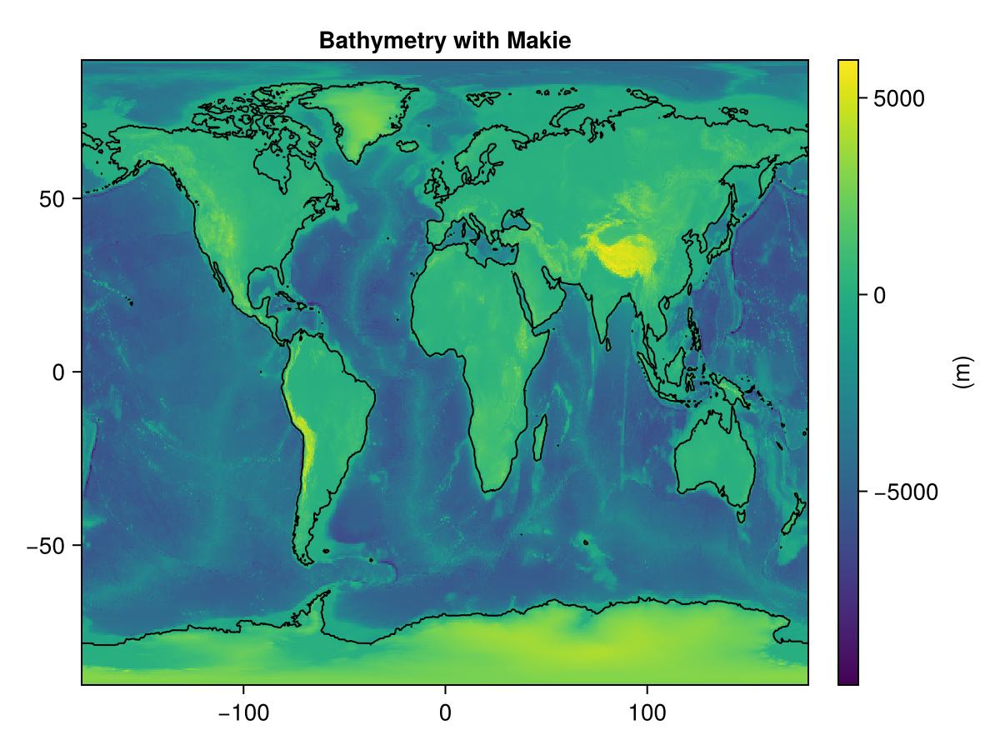

In [4]:
f = Figure()
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = heatmap!(ax, lon, lat, bathy)
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(f[1, 2], hm, label = "(m)")
f

Let's detail all the operations:
- `f` is the figure object;
- `ax` is the Axis, which can contain many options;
- `heatmap!` is the function that generate the plot;
- `contour!` is added to plot the coastline (i.e. where the bathymetry is equal to zero.

#### What can be improved?
The result obtained with the default settings is always something we can improve.
1. The colormap: we will select one from [ColorSchemes](https://docs.juliaplots.org/dev/generated/colorschemes/)
2. The color range: the values are computed from the data, but we can set them _by hand_;
3. The figure size: we can increase the default value (600 x 450 CSS pixels in web contexts).
4. The colorbar label: it can be left unrotated (i.e., horizontal).

In [5]:
### Change the colormap

In [6]:
using ColorSchemes
topocmap = ColorSchemes.delta

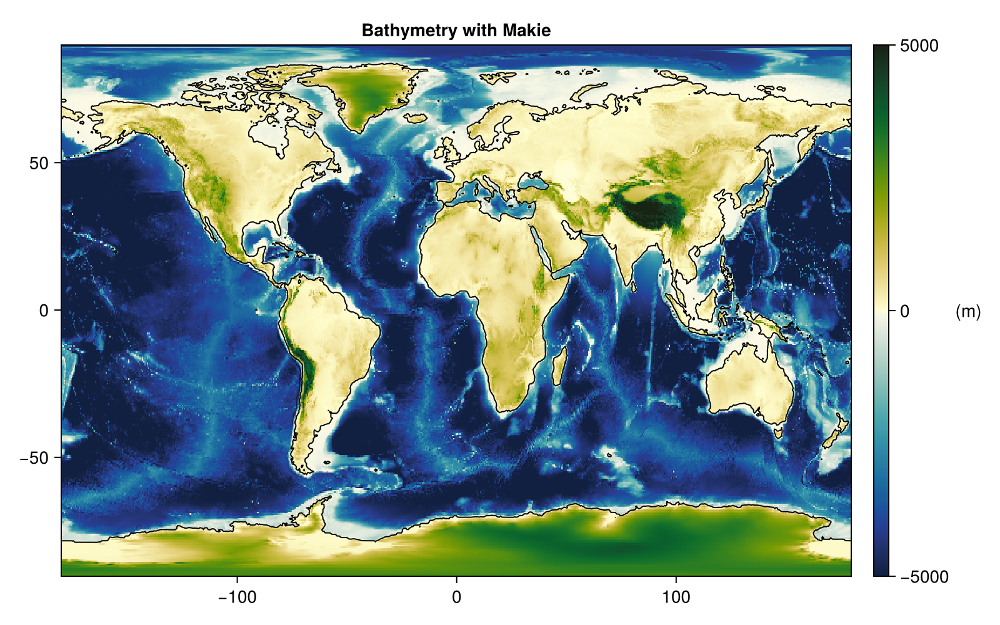

In [7]:
f = Figure(size = (800, 500))
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap, colorrange = [-5000, 5000])
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(f[1, 2], hm, label = "(m)", labelrotation = 0)
f

### Use non-symmetric values for lower and upper bound
In the previous map we set symmetric limits around zero (-5000 and 5000) in order to have the ocean in blue tones and the land in yellow/green. But this is not always the case.

The solution is to create a custom colormap.

In [21]:
lower = -6000.0
upper = 8000.0
zp = -lower / (upper - lower)        # position of 0 in [0, 1], ≈ 0.4286
cmap = cgrad(:delta)

n = 512
ts = range(0, 1; length = n)
topocmap2 = [t <= zp ? cmap[0.5*t/zp] : cmap[0.5+0.5*(t-zp)/(1-zp)] for t in ts]

The resulting map is as follows:

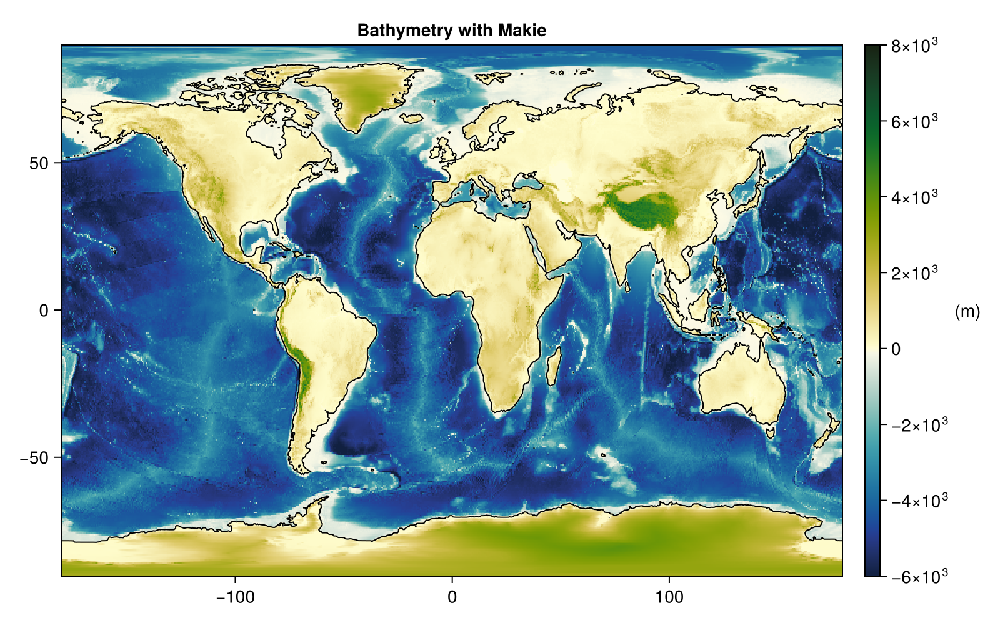

In [15]:
f = Figure(size = (800, 500))
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap2, colorrange = [lower, upper])
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(f[1, 2], hm, label = "(m)", labelrotation = 0)
f

Meanwhile, a new issue has come up: the colorbar tick labels are now written with exponents.     
This is solved by speficying the `tickformat`:

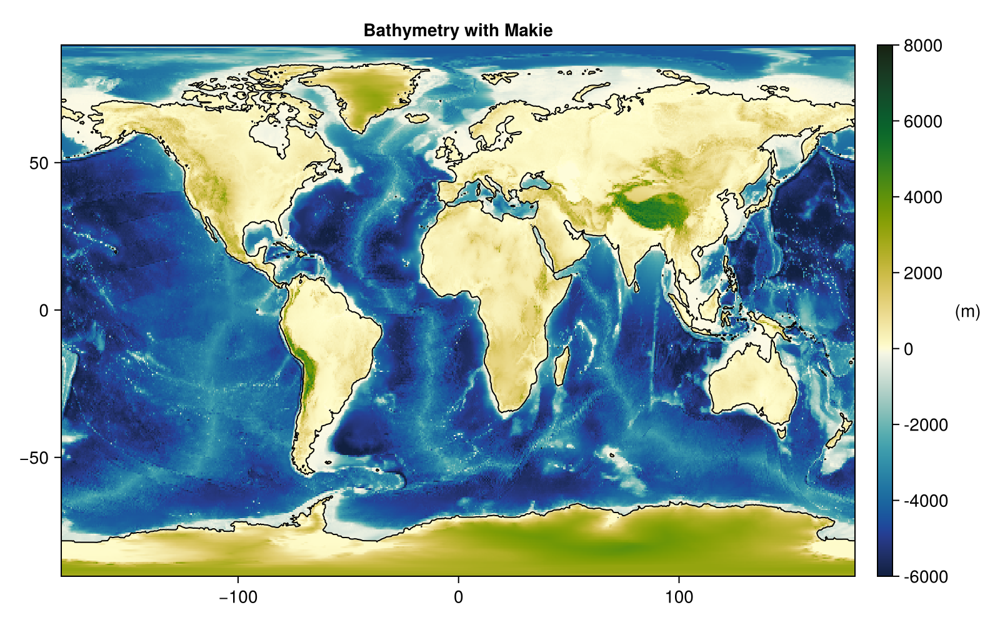

In [16]:
f = Figure(size = (800, 500))
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap2, colorrange = [lower, upper])
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(
    f[1, 2],
    hm,
    label = "(m)",
    labelrotation = 0,
    tickformat = values -> [string(round(Int, v)) for v in values],
)
f

### Surface
The function [`surface`](https://docs.makie.org/dev/reference/plots/surface) is another way to display 2D data. The default behaviour is different, as it performs interpolation and also shading effects. This can be avoided using the following options:    
- `shading=NoShading`
- `interpolate=false`

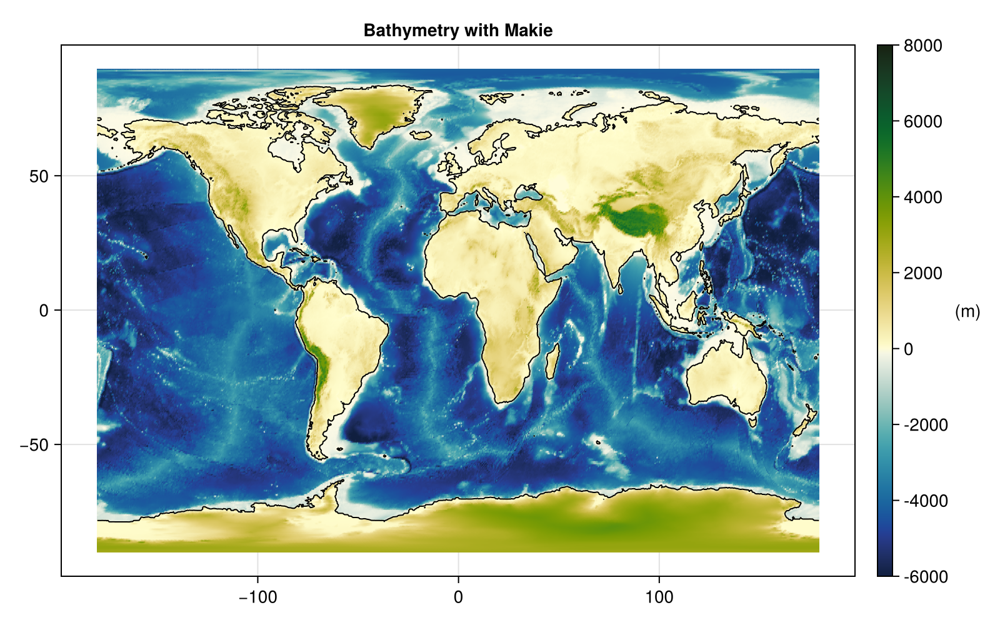

In [22]:
f = Figure(size = (800, 500))
ax = Axis(f[1, 1], title = "Bathymetry with Makie")
hm = surface!(
    ax,
    lon,
    lat,
    bathy,
    colormap = topocmap2,
    colorrange = [lower, upper],
    shading = NoShading,
    interpolate = false,
)
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(
    f[1, 2],
    hm,
    label = "(m)",
    labelrotation = 0,
    tickformat = values -> [string(round(Int, v)) for v in values],
)
f

A white band around the plot is now visible, we can remove it by specifying the map boundary:

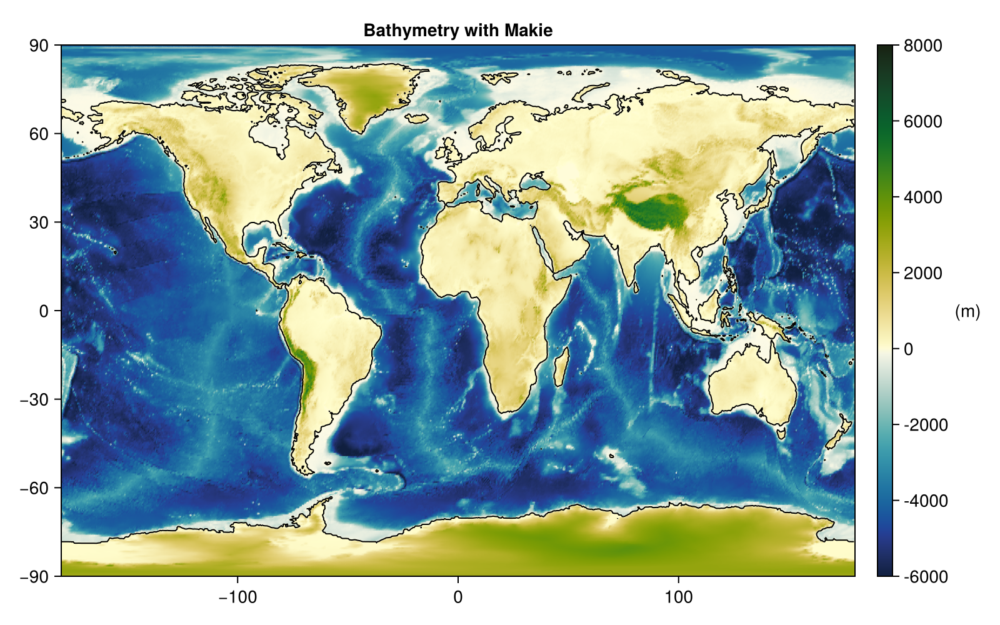

In [23]:
f = Figure(size = (800, 500))
ax = Axis(f[1, 1], title = "Bathymetry with Makie", limits = (-180, 180, -90, 90))
hm = surface!(
    ax,
    lon,
    lat,
    bathy,
    colormap = topocmap2,
    colorrange = [lower, upper],
    shading = NoShading,
    interpolate = false,
)
contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(
    f[1, 2],
    hm,
    label = "(m)",
    labelrotation = 0,
    tickformat = values -> [string(round(Int, v)) for v in values],
)
f

## Setting ticks to have degrees

In [48]:
lonformat(-130:10:10)

15-element Vector{AbstractString}:
 "-130°W"
 "-120°W"
 "-110°W"
 "-100°W"
 "-90°W"
 "-80°W"
 "-70°W"
 "-60°W"
 "-50°W"
 "-40°W"
 "-30°W"
 "-20°W"
 "-10°W"
 "0°"
 "abs(lon)°E"

In [47]:
function lonformat(lons)
    lonf = Vector{AbstractString}(undef, length(lons))
    for (iii, lon) in enumerate(lons)
        if lon == 0.0
            lonf[iii] = "0°"
        elseif lon > 0.0
            lonf[iii] = "$abs(lon)°E"
        else
            lonf[iii] = "$(lon)°W"
        end
    end
    return lonf
end

lonformat (generic function with 1 method)

In [42]:
f = Figure(size = (800, 500))
ax = Axis(
    f[1, 1],
    title = "Bathymetry with Makie",
    limits = (-180, 180, -90, 90),
    xtickformat = lonformat,
    ytickformat = ys -> [@sprintf("%.0f°%s", abs(y), y < 0 ? "S" : "N") for y in ys],
)
hm = heatmap!(ax, lon, lat, bathy, colormap = topocmap2, colorrange = [lower, upper])

contour!(ax, lon, lat, bathy, levels = [0.0], color = :black)
Colorbar(
    f[1, 2],
    hm,
    label = "(m)",
    labelrotation = 0,
    tickformat = values -> [string(round(Int, v)) for v in values],
)
f

LoadError: MethodError: no method matching isless(::Float64, ::Vector{Float64})
The function `isless` exists, but no method is defined for this combination of argument types.

[0mClosest candidates are:
[0m  isless([91m::Missing[39m, ::Any)
[0m[90m   @[39m [90mBase[39m [90m[4mmissing.jl:87[24m[39m
[0m  isless(::AbstractFloat, [91m::Union{StatsBase.PValue, StatsBase.TestStat}[39m)
[0m[90m   @[39m [36mStatsBase[39m [90m~/.julia/packages/StatsBase/TkBxP/src/[39m[90m[4mstatmodels.jl:47[24m[39m
[0m  isless(::T, [91m::T[39m) where T<:Union{Float16, Float32, Float64}
[0m[90m   @[39m [90mBase[39m [90m[4mfloat.jl:635[24m[39m
[0m  ...


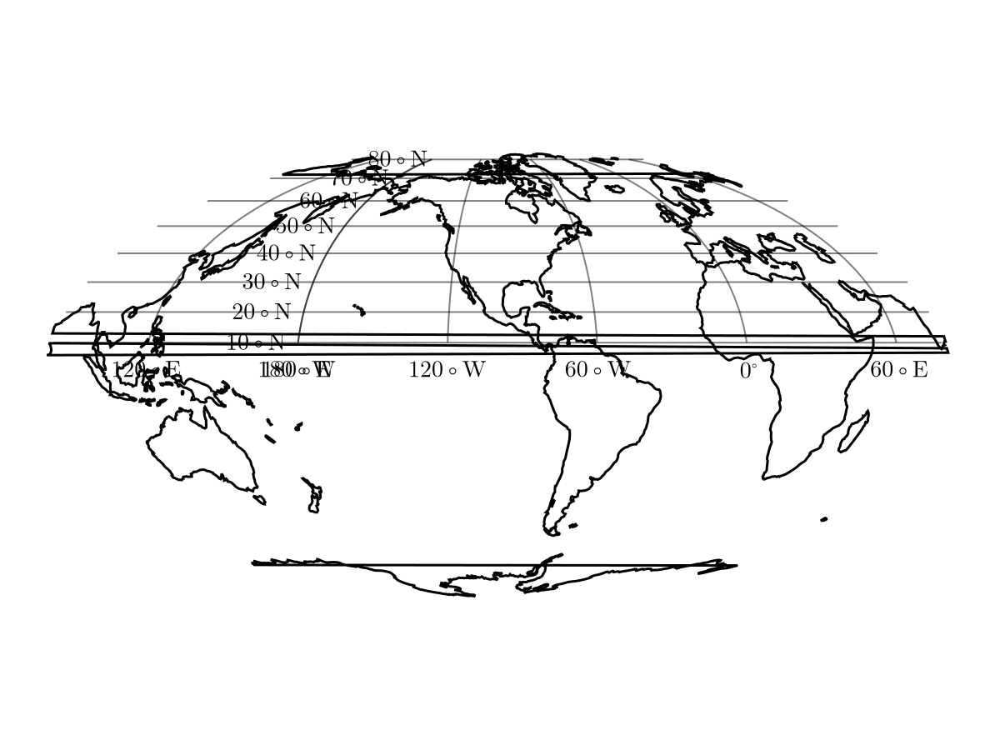

In [34]:
using CairoMakie
using GeoMakie
using LaTeXStrings

fig = Figure()

# 1. Define your desired tick positions
lon_ticks = -180:60:180
lat_ticks = 10:10:80

# 2. Build explicit labels (enforcing ONLY "0°" for 0)
lon_labels = [
    x == 0 ? L"0^\circ" :
    (
        x < 0 ? latexstring(abs(x), "\\circ\\mathrm{W}") :
        latexstring(abs(x), "\\circ\\mathrm{E}")
    ) for x in lon_ticks
]
lat_labels = [
    y == 0 ? L"0^\circ" :
    (
        y < 0 ? latexstring(abs(y), "\\circ\\mathrm{S}") :
        latexstring(abs(y), "\\circ\\mathrm{N}")
    ) for y in lat_ticks
]

# 3. Create the GeoAxis with default labels turned OFF
ga = GeoAxis(
    fig[1, 1];
    source = "+proj=longlat +datum=WGS84",
    dest = "+proj=moll +lat_0=45 +lon_0=-100",
    xticks = lon_ticks,
    yticks = lat_ticks,
    xticklabelsvisible = false, # Hide the native broken labels
    yticklabelsvisible = false,  # Hide the native broken labels
)

# 4. Draw the coastlines
lines!(ga, GeoMakie.coastlines(); color = :black)

# 5. Manually append your custom labels along the edges of the view
# Longitude labels placed along the bottom edge (adjust the latitude constant to fit your map boundary)
text!(
    ga,
    lon_ticks,
    fill(min(lat_ticks...) - 5, length(lon_ticks));
    text = lon_labels,
    align = (:center, :top),
    fontsize = 14,
)

# Latitude labels placed along the left edge (adjust the longitude constant to fit your map boundary)
text!(
    ga,
    fill(min(lon_ticks...) - 5, length(lat_ticks)),
    lat_ticks;
    text = lat_labels,
    align = (:right, :center),
    fontsize = 14,
)

fig
